Лабораторная работа 1
Сбор, визуализация и анализ данных по графу научных публикаций по тематике music за период с 2021 года. Работа выполняется шагами: загрузка данных, предобработка, анализ текста, построение графа ключевых слов, кластеризация, анализ центральности и поиск похожих публикаций.

Ячейка 1. Импорт библиотек и инициализация. Подключаются pandas, numpy, scipy.sparse, networkx, matplotlib, seaborn, sklearn и requests для работы с Arxiv API. Для выгрузки словарей nltk через настроенный прокси включается разрешение proxied fetch. Скачиваются стоп слова, корпус wordnet и токенизатор punkt.

In [30]:
import time
import warnings
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import nltk
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer

warnings.filterwarnings('ignore')

try:
    nltk.pathsec.ALLOW_PROXIED_FETCH = True
except AttributeError:
    pass

for corpus in ['stopwords', 'wordnet', 'punkt', 'punkt_tab', 'omw-1.4']:
    nltk.download(corpus, quiet=True)

plt.rcParams['figure.figsize'] = (12, 4)
sns.set_style('whitegrid')

Ячейка 2. Сбор данных через Arxiv API. Запрос all:music с фильтром по дате с 2021 года. Если файл arxiv_music_data.csv уже существует, он загружается, иначе данные скачиваются через requests, разбираются из XML и сохраняются в utf 8. Набор ограничен 1000 публикациями.

In [31]:
ARXIV_CSV = Path('arxiv_music_data.csv')
ARXIV_URL = (
    'https://export.arxiv.org/api/query'
    '?search_query=all:music+AND+submittedDate:[202101010000+TO+202612312359]'
    '&start=0'
    '&max_results=1000'
)
REQUEST_HEADERS = {'User-Agent': 'ITMO DataAnalysisLab (mailto:student@itmo.ru)'}
NAMESPACES = {'atom': 'http://www.w3.org/2005/Atom'}


def fetch_arxiv_feed(url: str) -> ET.Element:
    for attempt in range(3):
        try:
            response = requests.get(url, headers=REQUEST_HEADERS, timeout=120)
            response.raise_for_status()
            return ET.fromstring(response.content)
        except Exception as exc:
            if attempt == 2:
                raise RuntimeError('Ошибка загрузки данных с Arxiv API') from exc
            time.sleep(3)

results_limit = 1000

def load_arxiv_data(url: str, out_path: Path, limit: int = results_limit) -> pd.DataFrame:
    if out_path.exists():
        cached = pd.read_csv(out_path, encoding='utf-8')
        if len(cached) == limit:
            return cached
        print(f'Кеш содержит {len(cached)} строк, скачиваем набор на {limit}')
    root = fetch_arxiv_feed(url)
    papers = []
    for entry in root.findall('atom:entry', NAMESPACES):
        title = entry.find('atom:title', NAMESPACES).text.strip().replace('\n', ' ')
        summary = entry.find('atom:summary', NAMESPACES).text.strip().replace('\n', ' ')
        published = entry.find('atom:published', NAMESPACES).text
        year = int(published[:4])
        if year >= 2021:
            author_names = [a.find('atom:name', NAMESPACES).text for a in entry.findall('atom:author', NAMESPACES)]
            papers.append({'title': title, 'summary': summary, 'authors': '; '.join(author_names), 'year': year})
    result = pd.DataFrame(papers).head(limit)
    result.to_csv(out_path, index=False, encoding='utf-8')
    return result


df = load_arxiv_data(ARXIV_URL, ARXIV_CSV)
print(f'Загружено публикаций: {len(df)}')
print(f'Файл данных: {ARXIV_CSV.resolve()}')
df[['title', 'year']].head(3)

,title,year
0,Dorabella Cipher as Musical Inspiration,2025
1,Improving Choral Music Separation through Expr...,2022
2,musif: a Python package for symbolic music fea...,2023


Ячейка 3. Предобработка текста. Текст приводится к нижнему регистру и очищается от спецсимволов, затем токенизируется, освобождается от стоп слов и лемматизируется. Заголовок и аннотация каждой статьи объединяются в текстовое поле.

In [32]:
STOP_WORDS = set(stopwords.words('english'))
LEMMATIZER = WordNetLemmatizer()


def clean_text(text: str) -> str:
    reduced = ''.join(ch for ch in text.lower() if ch.isalpha() or ch.isspace())
    tokens = nltk.word_tokenize(reduced)
    tokens = [LEMMATIZER.lemmatize(word) for word in tokens if word not in STOP_WORDS and len(word) > 2]
    return ' '.join(tokens)


df['clean_text'] = (df['title'] + ' ' + df['summary']).apply(clean_text)
df[['title', 'clean_text']].head(2)

,title,clean_text
0,Dorabella Cipher as Musical Inspiration,dorabella cipher musical inspiration dorabella...
1,Improving Choral Music Separation through Expr...,improving choral music separation expressive s...


Ячейка 4. Разведочный анализ данных. Строятся два графика: распределение статей по годам и гистограмма длины текстов. Далее проверяется закон Ципфа на лог лог графике с теоретической кривой вида c / x.

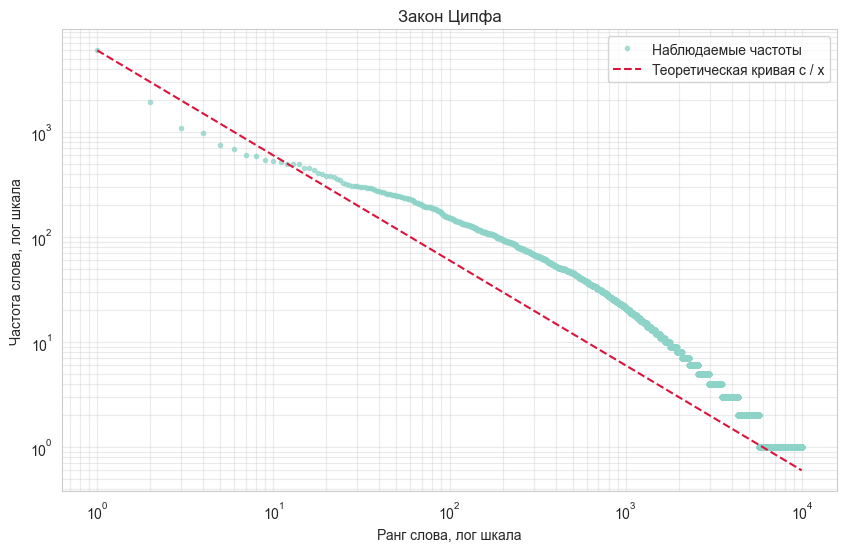

In [33]:
fig, axes = plt.subplots(1, 2)
ax_year = axes[0]
df['year'].value_counts().sort_index().plot(kind='bar', ax=ax_year, color='steelblue')
ax_year.set_title('Число статей по годам')
ax_year.set_xlabel('Год')
ax_year.set_ylabel('Число публикаций')

ax_length = axes[1]
text_lengths = df['clean_text'].str.split().str.len()
ax_length.hist(text_lengths, bins=30, color='teal', edgecolor='white')
ax_length.set_title('Длина текстов в словах')
ax_length.set_xlabel('Число слов')
ax_length.set_ylabel('Частота')
plt.tight_layout()
plt.show()

word_corpus = ' '.join(df['clean_text']).split()
frequencies = pd.Series(Counter(word_corpus)).sort_values(ascending=False)
ranks = np.arange(1, len(frequencies) + 1)
constant = frequencies.iloc[0]

plt.figure(figsize=(10, 6))
plt.loglog(ranks, frequencies.to_numpy(), marker='.', linestyle='none', alpha=0.7, label='Наблюдаемые частоты')
plt.loglog(ranks, constant / ranks, linestyle='dashed', color='crimson', label='Теоретическая кривая c / x')
plt.title('Закон Ципфа')
plt.xlabel('Ранг слова, лог шкала')
plt.ylabel('Частота слова, лог шкала')
plt.grid(True, which='both', alpha=0.4)
plt.legend()
plt.show()

Ячейка 5. Выделение ключевых слов. Используется TfidfVectorizer с диапазоном ngram от 1 до 3 и ограничением на 800 признаков. Термины с низким максимальным значением tf idf отбрасываются, чтобы оставить только значимые слова.

In [34]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 3),
    max_features=800,
    sublinear_tf=True,
    stop_words='english',
)
X = vectorizer.fit_transform(df['clean_text'])
all_terms = vectorizer.get_feature_names_out()
peak_tfidf = X.max(axis=0).toarray().ravel()
kept_terms = peak_tfidf >= 0.05
X = X[:, kept_terms]
keywords = all_terms[kept_terms]
print(f'Ключевых слов отобрано: {sum(kept_terms)} из {len(all_terms)}')

Ключевых слов отобрано: 800 из 800


Ячейка 6. Построение графа ключевых слов. Матрица со встречаемости вычисляется разреженно через умножение бинарной матрицы на её транспонированную версию. Добавляются ребра с весом не менее 2, граф визуализируется с помощью spring layout.

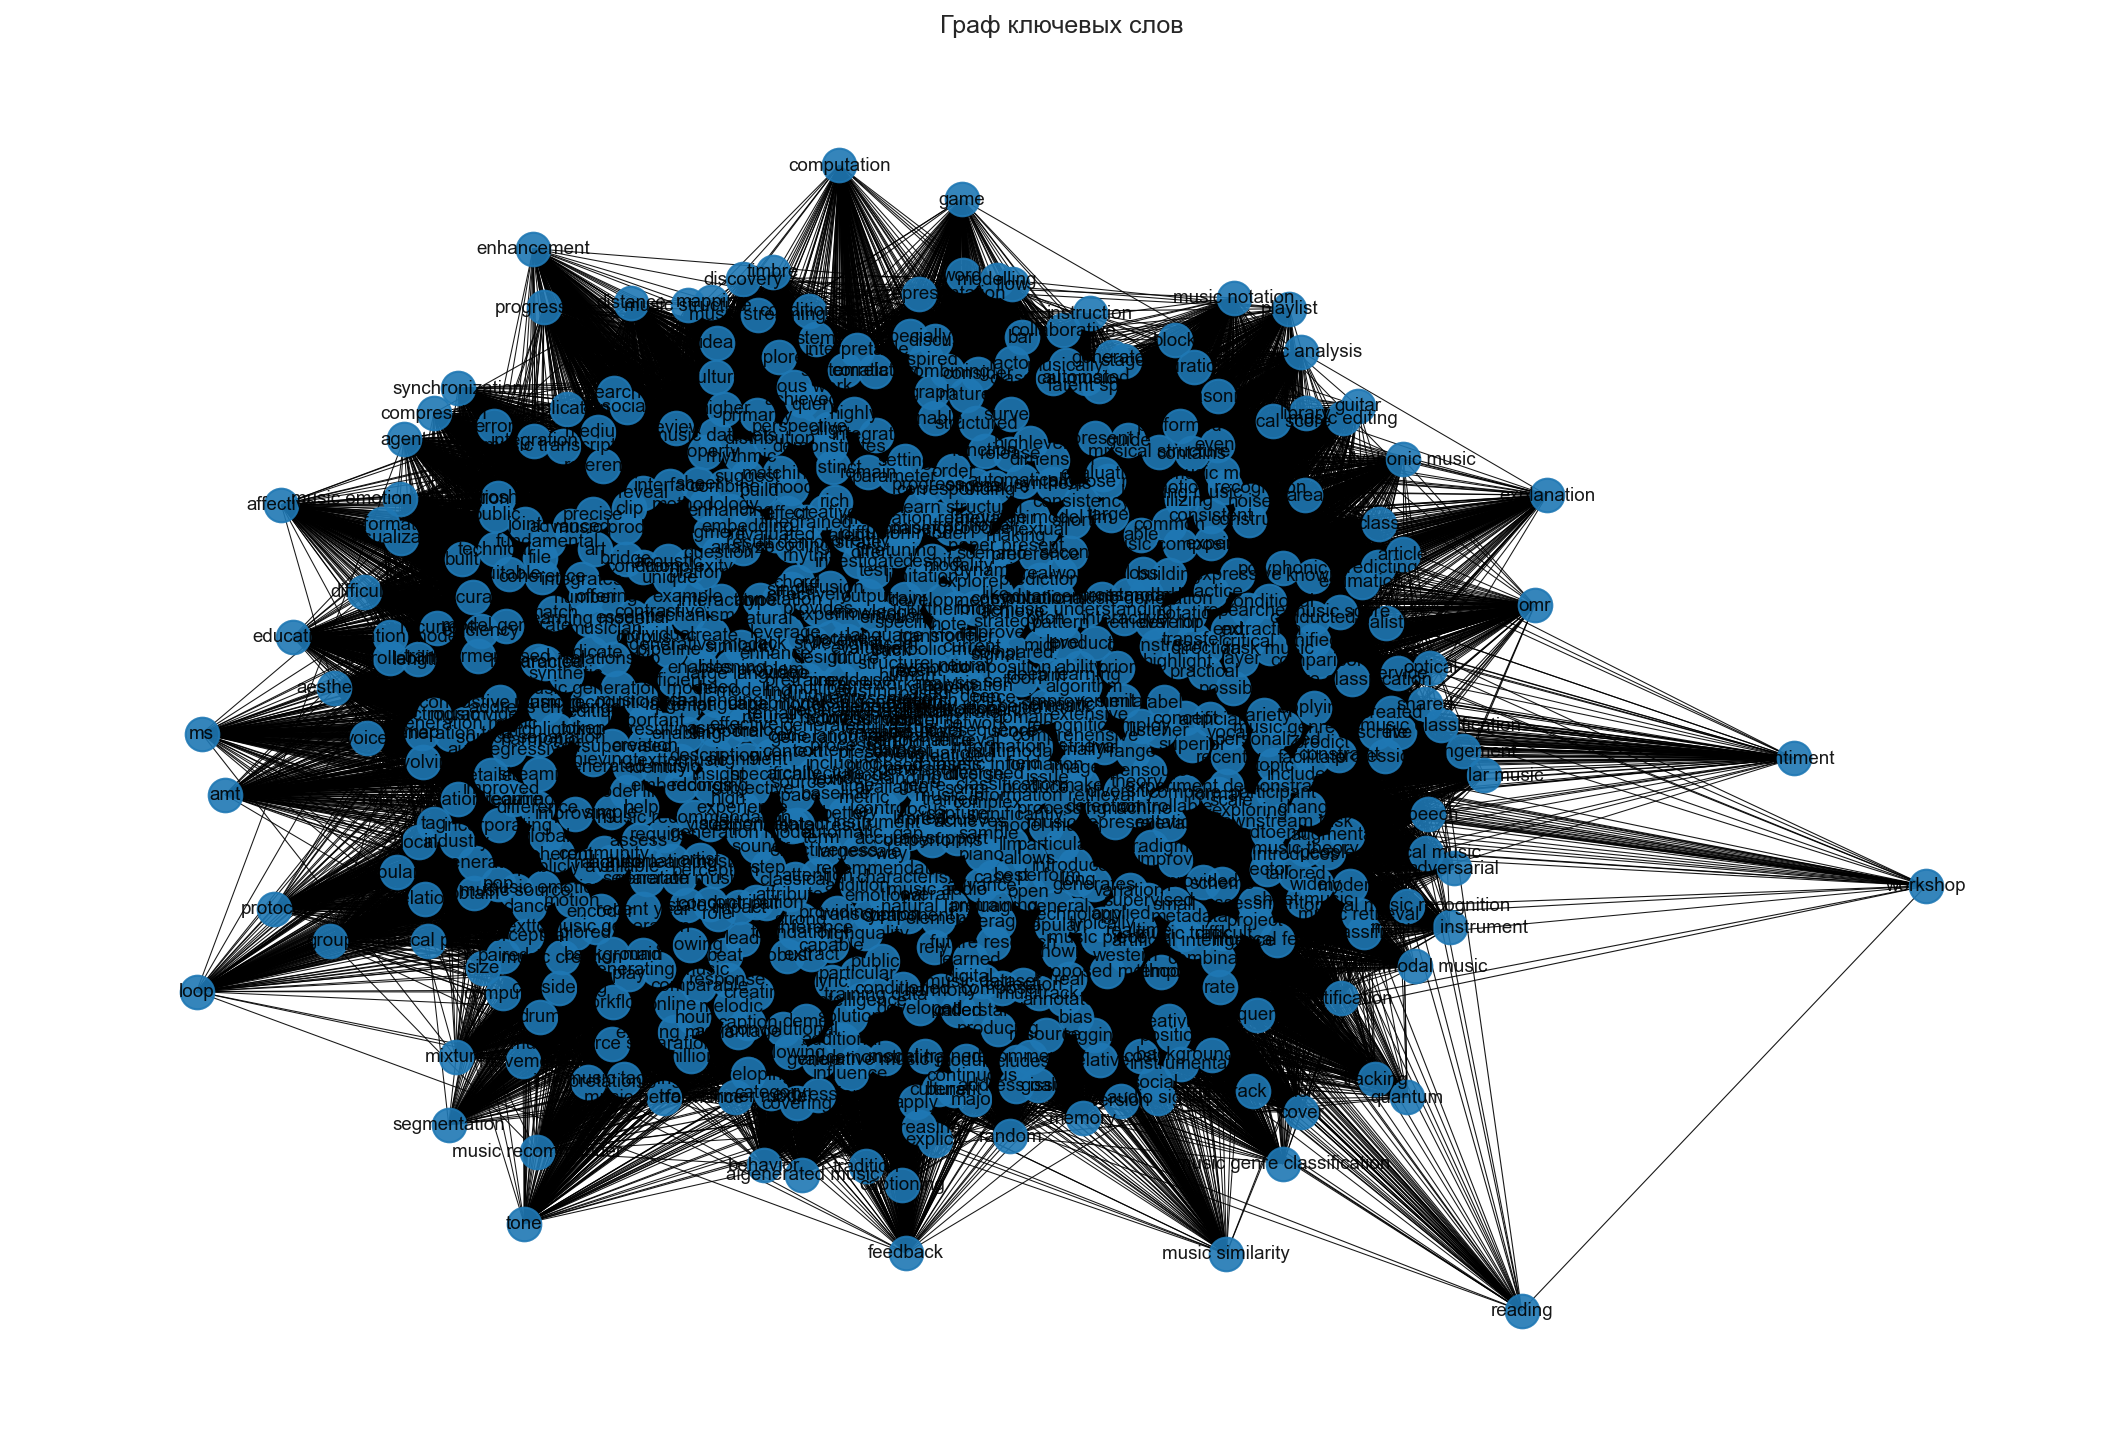

In [35]:
X_bin = (X > 0).astype(int)
cooccurrence = (X_bin.T @ X_bin).tocoo()

keyword_graph = nx.Graph()
keyword_graph.add_nodes_from(keywords.tolist())

for i, j, weight in zip(cooccurrence.row, cooccurrence.col, cooccurrence.data):
    if i < j and weight >= 2:
        keyword_graph.add_edge(keywords[i], keywords[j], weight=int(weight))

keyword_graph.remove_nodes_from(list(nx.isolates(keyword_graph)))
print(f'Граф ключевых слов: {keyword_graph.number_of_nodes()} узлов, {keyword_graph.number_of_edges()} ребер')

pos = nx.spring_layout(keyword_graph, seed=42, weight='weight', k=0.8)
max_weight = max(keyword_graph[u][v]['weight'] for u, v in keyword_graph.edges())
edge_widths = [0.5 + 3.5 * keyword_graph[u][v]['weight'] / max_weight for u, v in keyword_graph.edges()]
plt.figure(figsize=(18, 12), dpi=150)
nx.draw_networkx(keyword_graph, pos, with_labels=True, node_size=260, font_size=9, alpha=0.9, width=edge_widths)
plt.title('Граф ключевых слов')
plt.axis('off')
plt.savefig('keyword_graph.png', dpi=200, bbox_inches='tight')
plt.show()

Ячейка 7. Кластеризация графа. Применяется жадная максимизация модулярности. Выводится значение модулярности и слова каждого кластера. Визуализация окрашена по кластерам, что показывает смысловые тематики внутри корпуса.

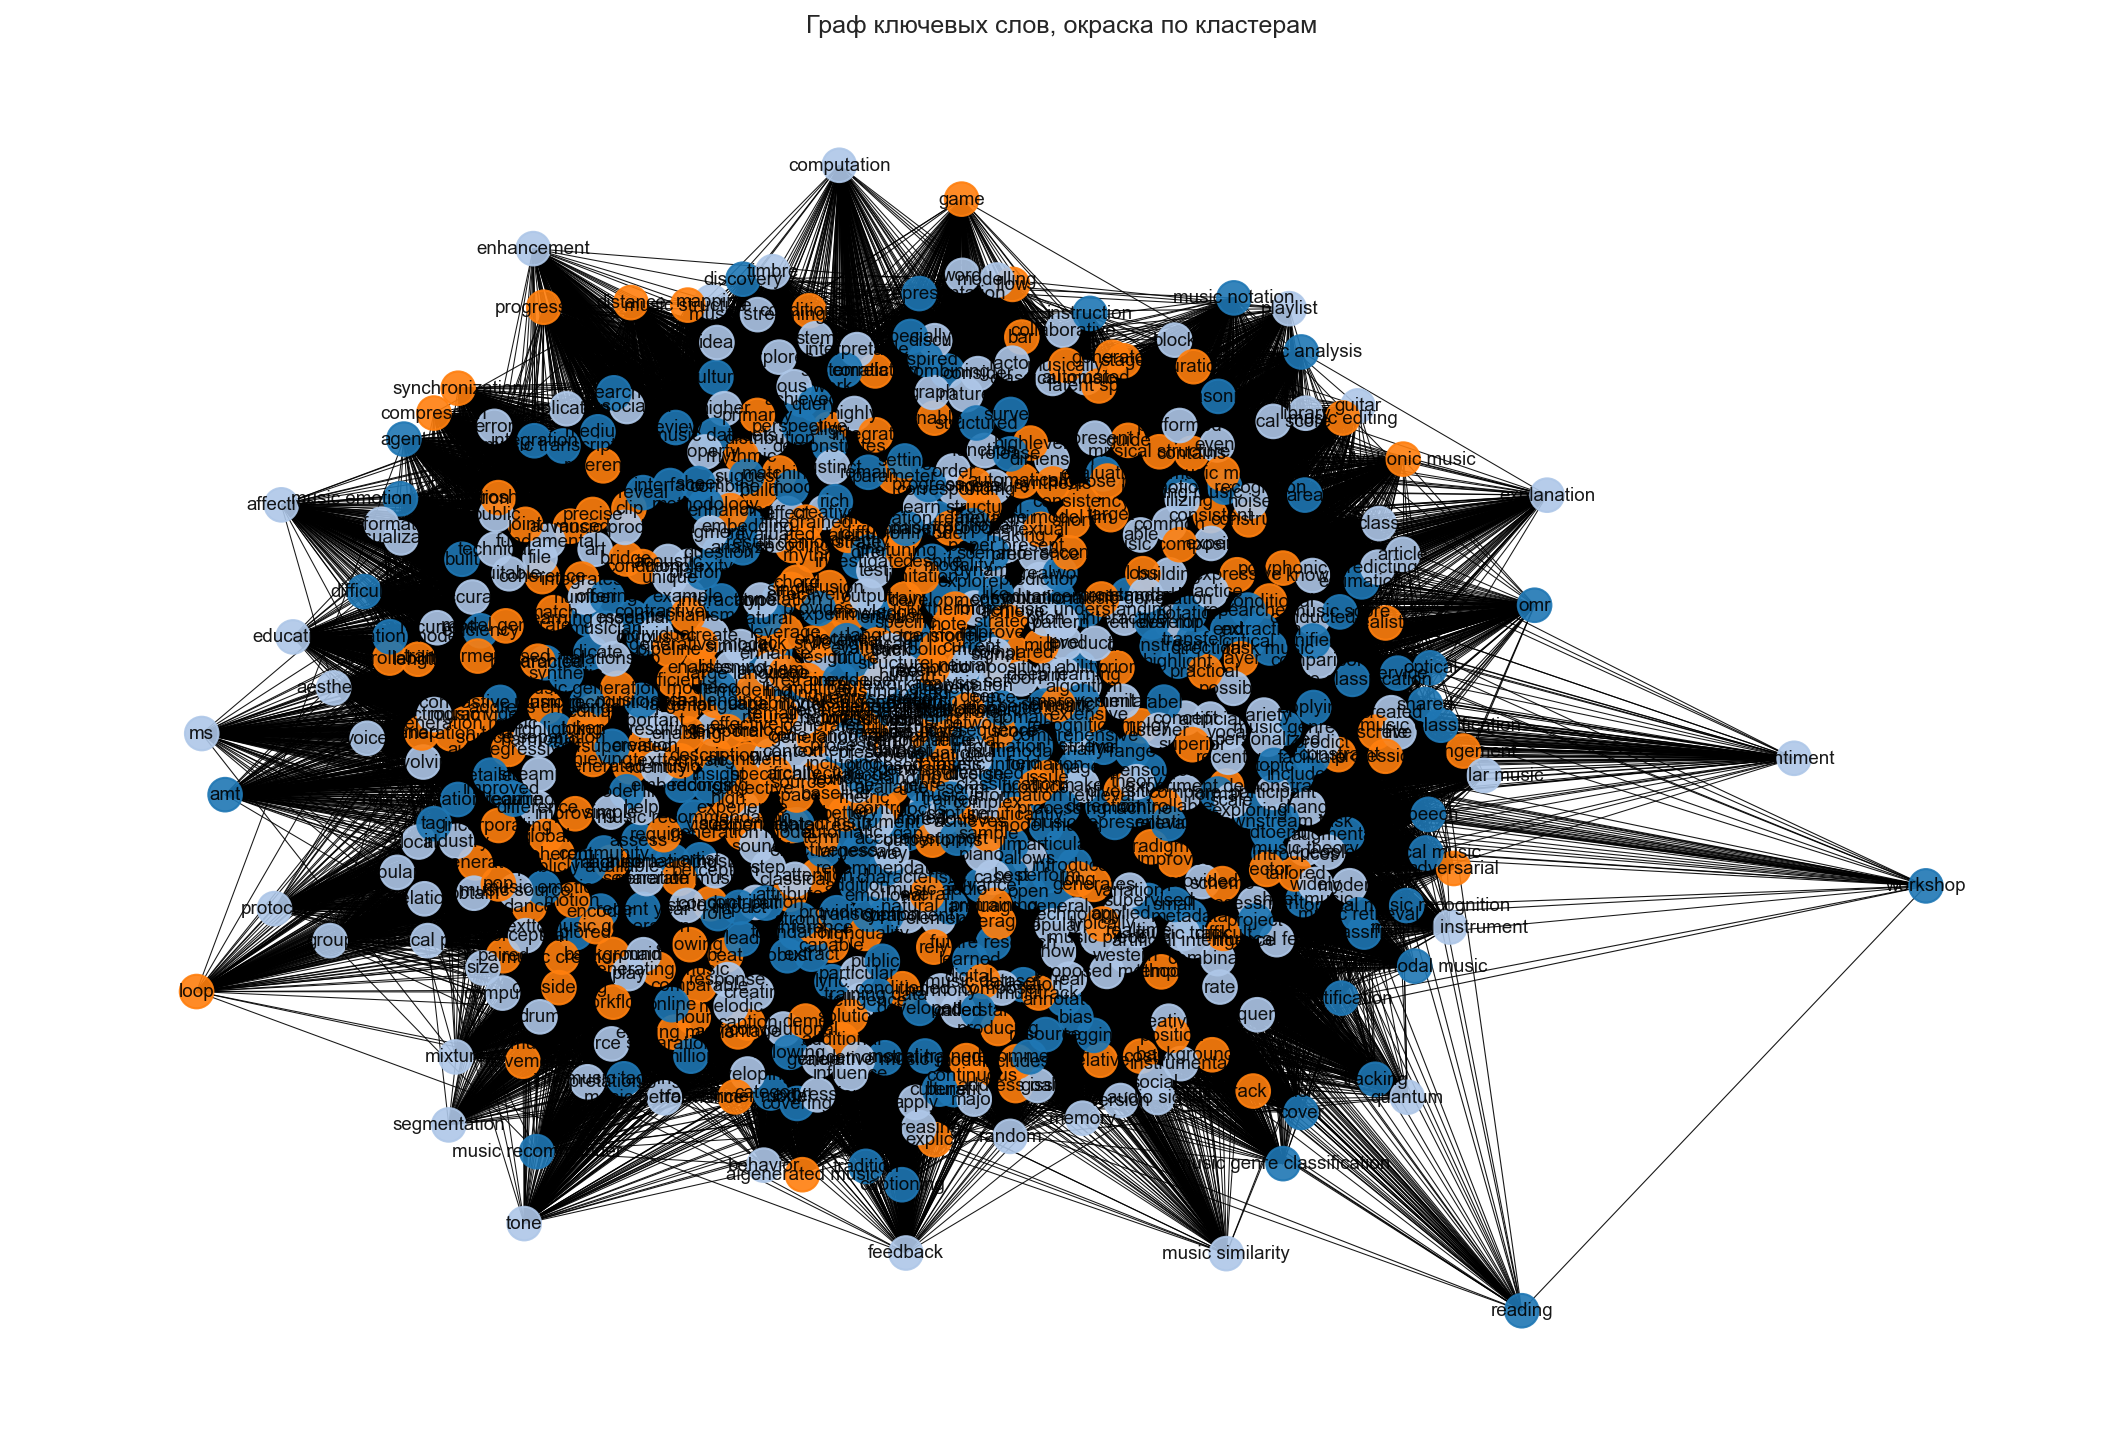

In [36]:
communities = list(nx.algorithms.community.greedy_modularity_communities(keyword_graph, weight='weight'))
modularity = nx.algorithms.community.modularity(keyword_graph, communities, weight='weight')
print(f'Модулярность: {modularity:.4f}')

node_cluster = {}
for cluster_index, community in enumerate(communities):
    words = sorted(community)
    node_cluster.update({word: cluster_index for word in words})
    print(f'Кластер {cluster_index} из {len(words)} слов: {", ".join(words)}')

pos = nx.spring_layout(keyword_graph, seed=42, weight='weight', k=0.8)
cmap = plt.get_cmap('tab20')
colors = [cmap(node_cluster[node] % 20) for node in keyword_graph.nodes()]
max_weight = max(keyword_graph[u][v]['weight'] for u, v in keyword_graph.edges())
edge_widths = [0.5 + 3.5 * keyword_graph[u][v]['weight'] / max_weight for u, v in keyword_graph.edges()]
plt.figure(figsize=(18, 12), dpi=150)
nx.draw_networkx(keyword_graph, pos, node_color=colors, with_labels=True, node_size=260, font_size=9, alpha=0.9, width=edge_widths)
plt.title('Граф ключевых слов, окраска по кластерам')
plt.axis('off')
plt.savefig('keyword_graph_clusters.png', dpi=200, bbox_inches='tight')
plt.show()

Ячейка 8. Анализ центральности. Для каждой метрики выводится топ 5 ключевых слов. Degree показывает общую связанность, betweenness выделяет слова мосты между тематиками, closeness отражает близость ко всем узлам, eigenvector подчеркивает соседей влиятельных слов.

In [37]:
degree_centrality = nx.degree_centrality(keyword_graph)
betweenness_centrality = nx.betweenness_centrality(keyword_graph, weight='weight')
closeness_centrality = nx.closeness_centrality(keyword_graph)

try:
    eigenvector_centrality = nx.eigenvector_centrality(keyword_graph, weight='weight', max_iter=1000)
except nx.PowerIterationFailedConvergence:
    eigenvector_centrality = nx.eigenvector_centrality_numpy(keyword_graph, weight='weight')


def top_words(centrality: dict[str, float], top_n: int = 5) -> list[tuple[str, float]]:
    return sorted(centrality.items(), key=lambda pair: pair[1], reverse=True)[:top_n]


for metric_name, values in {
    'Degree': degree_centrality,
    'Betweenness': betweenness_centrality,
    'Eigenvector': eigenvector_centrality,
    'Closeness': closeness_centrality,
}.items():
    print(f'Топ 5 по {metric_name}:')
    for word, score in top_words(values):
        print(f'  {word}: {score:.4f}')

Топ 5 по Degree:
  music: 1.0000
  method: 0.9987
  model: 0.9987
  musical: 0.9987
  result: 0.9987
Топ 5 по Betweenness:
  online: 0.0055
  reading: 0.0038
  reasoning: 0.0032
  agent: 0.0029
  affective: 0.0027
Топ 5 по Eigenvector:
  music: 0.3165
  model: 0.2412
  musical: 0.1828
  generation: 0.1521
  method: 0.1400
Топ 5 по Closeness:
  music: 1.0000
  method: 0.9988
  model: 0.9988
  musical: 0.9988
  result: 0.9988


Ячейка 9. Граф публикаций и поиск. Матрица смежности публикаций получена разреженным умножением, вес ребра равен числу общих ключевых слов. Функция search_similar_papers находит целевую статью по запросу и возвращает самые близкие статьи из графа.

In [38]:
paper_adjacency = (X_bin @ X_bin.T).tocoo()

paper_graph = nx.Graph()
paper_graph.add_nodes_from(df.index.tolist())

for i, j, weight in zip(paper_adjacency.row, paper_adjacency.col, paper_adjacency.data):
    if i < j and weight >= 1:
        paper_graph.add_edge(int(i), int(j), weight=int(weight))

print(f'Граф публикаций: {paper_graph.number_of_nodes()} узлов, {paper_graph.number_of_edges()} ребер')


def search_similar_papers(query: str, data: pd.DataFrame, graph: nx.Graph, top_n: int = 3) -> list[tuple[int, int]]:
    query_terms = set(clean_text(query).split())
    overlap = data['clean_text'].apply(lambda text: len(query_terms.intersection(text.split())))
    if overlap.max() == 0:
        overlap = data['title'].str.contains(query.split()[0], case=False, na=False).astype(int)
    target = int(overlap.idxmax())
    neighbors = sorted(
        ((neighbor, graph[target][neighbor]['weight']) for neighbor in graph.neighbors(target)),
        key=lambda pair: pair[1],
        reverse=True,
    )[:top_n]
    print(f'Исходная публикация: {data.loc[target, "title"]}')
    for pub_id, weight in neighbors:
        print(f'  Похожая статья с весом {weight}: {data.loc[pub_id, "title"]}')
    return [(pub_id, weight) for pub_id, weight in neighbors]

Граф публикаций: 1000 узлов, 498444 ребер


Ячейка 10. Тестирование поиска. Выполняется вызов функции с запросом deep learning music generation и с заголовком существующей статьи из датасета. Выводится исходная статья и похожие публикации с весами связей.

In [39]:
search_similar_papers('deep learning music generation', df, paper_graph)
search_similar_papers(df.iloc[0]['title'], df, paper_graph)

[(801, 12), (264, 11), (263, 10)]